In [1]:
import numpy as np
from matplotlib import pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from math import ceil

In [2]:
train_ds, test_ds = tfds.load('imagenette/160px-v2', split=['train', 'validation'], as_supervised=True)
train_ds = train_ds.map(lambda x, y: (2. * tf.image.convert_image_dtype(tf.image.resize(x, (224, 224)), dtype=tf.float32) - 1., tf.one_hot(y, depth=10)))
test_ds = test_ds.map(lambda x, y: (2. * tf.image.convert_image_dtype(tf.image.resize(x, (224, 224)), dtype=tf.float32) - 1., tf.one_hot(y, depth=10)))

2024-02-05 10:53:00.430436: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-02-05 10:53:00.888033: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 46962 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [7]:
classes = ['tench', 'English springer', 'cassette player', 'chain saw', 'church', 'French horn', 'garbage truck', 'gas pump', 'golf ball', 'parachute']

In [14]:
np.where(lab.numpy()==1.0)[0][0]

2

2024-02-05 11:05:53.022061: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


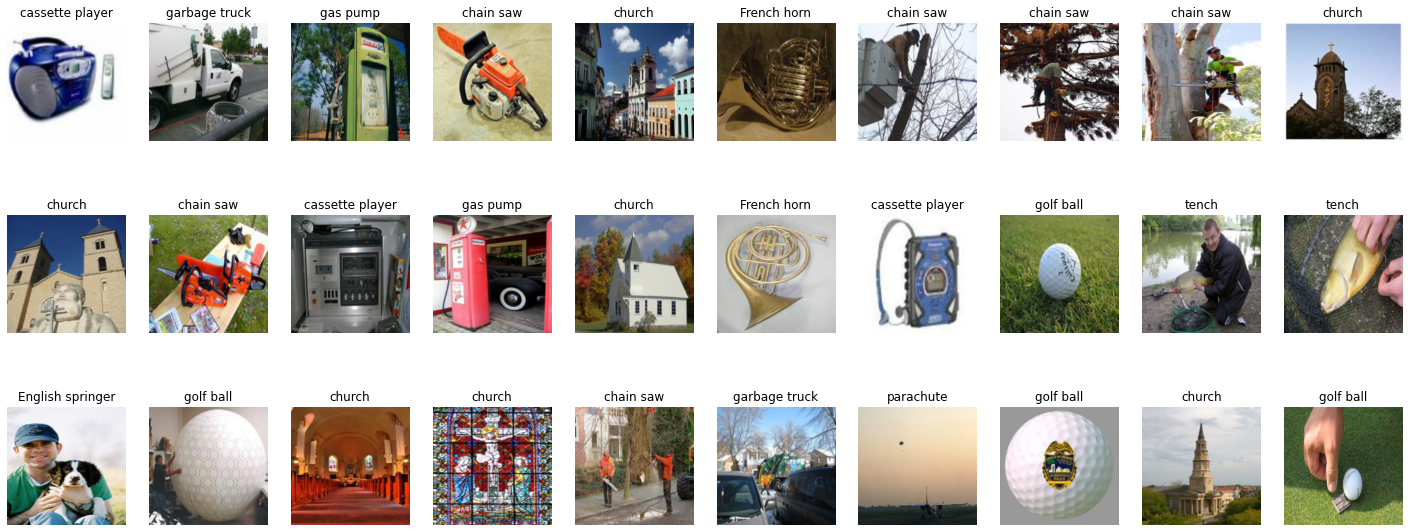

In [18]:
iter_train = iter(train_ds)
example_batch = []
for _ in range(30):
    img, label = next(iter_train)
    example_batch.append((img, label))

plt.rcParams["figure.figsize"] = [25, 10]
for img_id, (img, lab) in enumerate(example_batch):
    plt.subplot(3, len(example_batch)//3, img_id+1)
    plt.imshow((img + 1) / 255. / 2.)
    plt.title(classes[np.where(lab.numpy()==1.0)[0][0]])
    plt.axis('off')

In [8]:
from tensorflow.keras import Sequential
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Lambda
from tensorflow.keras.losses import CategoricalCrossentropy, Reduction
from tensorflow.keras.optimizers import Adam

In [9]:
base_model = ResNet50(input_shape=(224, 224, 3), weights='imagenet', include_top=False)
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(10, kernel_initializer=tf.ones_initializer, use_bias=False)
])
loss_fn = CategoricalCrossentropy(from_logits=True)
optimizer = Adam(learning_rate=1e-4)
model.compile(loss=loss_fn, optimizer=optimizer, metrics=['accuracy'])
model.fit(train_ds.batch(32), epochs=2, validation_data=test_ds.batch(32), verbose=1)
model.evaluate(test_ds.batch(128), verbose=2)

Epoch 1/2


2024-02-04 18:37:36.548870: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2024-02-04 18:37:37.036291: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-02-04 18:37:37.037341: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-02-04 18:37:37.037401: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2024-02-04 18:37:37.038628: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-02-04 18:37:37.051363: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


296/296 [==============================] - 51s 153ms/step - loss: 0.4290 - accuracy: 0.8880 - val_loss: 0.2497 - val_accuracy: 0.9271
Epoch 2/2
296/296 [==============================] - 43s 146ms/step - loss: 0.0772 - accuracy: 0.9782 - val_loss: 0.1641 - val_accuracy: 0.9503
31/31 - 8s - loss: 0.1641 - accuracy: 0.9503 - 8s/epoch - 271ms/step


[0.16409622132778168, 0.950318455696106]

In [13]:
model.save_weights('./beexplainable/models/all/Imagenette/ResNet50_Imagenette.h5')

In [14]:
del model

In [16]:
base_model = ResNet50(input_shape=(224, 224, 3), weights='imagenet', include_top=False)
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(10, kernel_initializer=tf.ones_initializer, use_bias=False)
])
loss_fn = CategoricalCrossentropy(from_logits=True)
optimizer = Adam(learning_rate=1e-4)
model.load_weights('./beexplainable/models/all/Imagenette/ResNet50_Imagenette.h5')
model.compile(loss=loss_fn, optimizer=optimizer, metrics=['accuracy'])
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resnet50 (Functional)       (None, 7, 7, 2048)        23587712  
                                                                 
 global_average_pooling2d_1   (None, 2048)             0         
 (GlobalAveragePooling2D)                                        
                                                                 
 dense_1 (Dense)             (None, 10)                20480     
                                                                 
Total params: 23,608,192
Trainable params: 23,555,072
Non-trainable params: 53,120
_________________________________________________________________
